# Lab 03 - Perceptron and Weight Initialization

**Name:** Zain Ul Wahaj  
**Roll Number:** FA23-BAI-058  
**Course:** Artificial Neural Networks  

---

Complete solution to all **9 tasks** of Lab 03. Each part is solved in its own
code cell, directly below the question it answers, with its output shown underneath.

### Contents

1. **Task 1** - Dataset Loading and Visualization
2. **Task 2** - Basic Perceptron Implementation
3. **Task 3** - Perceptron Learning Curve and Weight Visualization
4. **Task 4** - Gaussian Weight Initialization
5. **Task 5** - Xavier/Glorot Initialization
6. **Task 6** - He/Kaiming Initialization
7. **Task 7** - Orthogonal Initialization
8. **Task 8** - Comparative Analysis of Weight Initialization Techniques
9. **Task 9** - Experimental Study and Interpretation


In [1]:
# Zain Ul Wahaj | FA23-BAI-058
# Artificial Neural Networks - Lab 03 - Perceptron and Weight Initialization

import numpy as np

NAME = "Zain Ul Wahaj"
ROLL_NUMBER = "FA23-BAI-058"

print("Name        :", NAME)
print("Roll Number :", ROLL_NUMBER)
print("Course      :", "Artificial Neural Networks")
print("Lab         :", "Lab 03 - Perceptron and Weight Initialization")
print("NumPy       :", np.__version__)

Name        : Zain Ul Wahaj
Roll Number : FA23-BAI-058
Course      : Artificial Neural Networks
Lab         : Lab 03 - Perceptron and Weight Initialization
NumPy       : 2.5.3


---

## Task 1: Dataset Loading and Visualization

**Topic:** Loading a binary-classification dataset, inspection, plotting, train/test split

### Task 1 (a)

> Select and load a suitable binary-classification dataset from Kaggle or the UCI Machine Learning Repository.

In [2]:
# Zain Ul Wahaj | FA23-BAI-058 | Task 1 (a)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

%matplotlib inline
plt.rcParams["figure.figsize"] = (8, 4.5)

SEED = 58                      # from roll number FA23-BAI-058, keeps runs reproducible

# Breast Cancer Wisconsin (Diagnostic) - UCI Machine Learning Repository.
# It ships with scikit-learn, so the notebook runs offline with no download.
data = load_breast_cancer()

X = data.data
y = data.target                # 0 = malignant, 1 = benign

print("Dataset : Breast Cancer Wisconsin (Diagnostic), UCI ML Repository")
print("Source  : sklearn.datasets.load_breast_cancer()")
print("Samples :", X.shape[0])
print("Features:", X.shape[1])
print("Classes :", dict(zip(data.target_names, np.bincount(y))))

Dataset : Breast Cancer Wisconsin (Diagnostic), UCI ML Repository
Source  : sklearn.datasets.load_breast_cancer()
Samples : 569
Features: 30
Classes : {np.str_('malignant'): np.int64(212), np.str_('benign'): np.int64(357)}


### Task 1 (b)

> Perform basic data inspection, including dataset shape, features, target variable, and missing values.

In [3]:
# Zain Ul Wahaj | FA23-BAI-058 | Task 1 (b)
df = pd.DataFrame(X, columns=data.feature_names)
df["target"] = y

print("Shape (rows, columns):", df.shape)
print("\nFirst 5 feature names:", list(data.feature_names[:5]))
print("Last 5 feature names :", list(data.feature_names[-5:]))

print("\nTarget variable")
print("   names  :", list(data.target_names))
print("   counts :", np.bincount(y), "-> 0 = malignant, 1 = benign")
print("   balance: {:.1f}% benign".format(100 * y.mean()))

print("\nMissing values across all columns:", int(df.isnull().sum().sum()))

print("\nSummary of the first four features:")
print(df.iloc[:, :4].describe().round(3))

Shape (rows, columns): (569, 31)

First 5 feature names: [np.str_('mean radius'), np.str_('mean texture'), np.str_('mean perimeter'), np.str_('mean area'), np.str_('mean smoothness')]
Last 5 feature names : [np.str_('worst compactness'), np.str_('worst concavity'), np.str_('worst concave points'), np.str_('worst symmetry'), np.str_('worst fractal dimension')]

Target variable
   names  : [np.str_('malignant'), np.str_('benign')]
   counts : [212 357] -> 0 = malignant, 1 = benign
   balance: 62.7% benign

Missing values across all columns: 0

Summary of the first four features:
       mean radius  mean texture  mean perimeter  mean area
count      569.000       569.000         569.000    569.000
mean        14.127        19.290          91.969    654.889
std          3.524         4.301          24.299    351.914
min          6.981         9.710          43.790    143.500
25%         11.700        16.170          75.170    420.300
50%         13.370        18.840          86.240    551.

### Task 1 (c)

> Visualize the dataset using appropriate plots to understand the distribution of the classes.

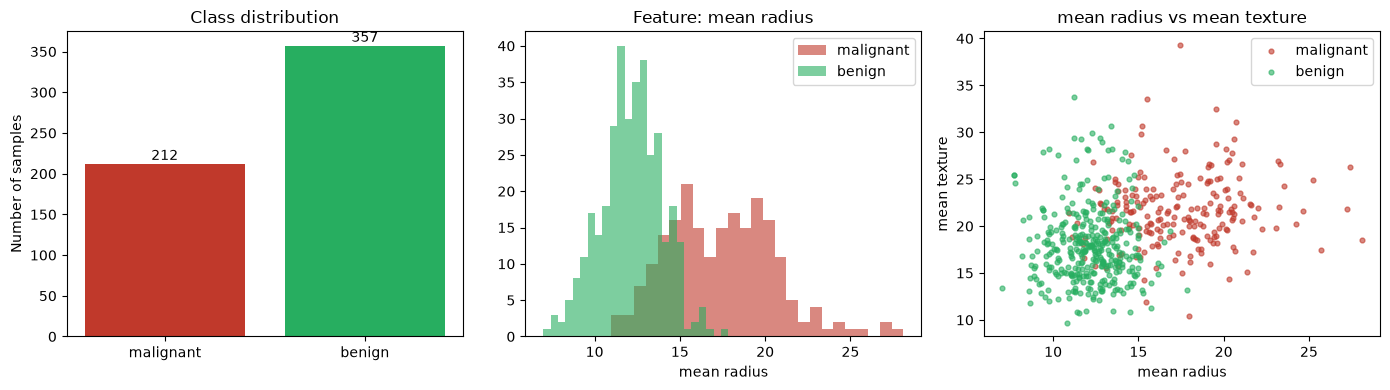

The classes overlap but are largely separated, which suits a linear model.


In [4]:
# Zain Ul Wahaj | FA23-BAI-058 | Task 1 (c)
fig, axes = plt.subplots(1, 3, figsize=(14, 4))

# 1. How many samples per class
counts = np.bincount(y)
axes[0].bar(data.target_names, counts, color=["#c0392b", "#27ae60"])
axes[0].set_title("Class distribution")
axes[0].set_ylabel("Number of samples")
for i, c in enumerate(counts):
    axes[0].text(i, c + 5, str(c), ha="center")

# 2. Does a single feature separate the classes?
for cls, colour, label in [(0, "#c0392b", "malignant"), (1, "#27ae60", "benign")]:
    axes[1].hist(X[y == cls, 0], bins=25, alpha=0.6, color=colour, label=label)
axes[1].set_title("Feature: mean radius")
axes[1].set_xlabel("mean radius")
axes[1].legend()

# 3. Two features together
for cls, colour, label in [(0, "#c0392b", "malignant"), (1, "#27ae60", "benign")]:
    axes[2].scatter(X[y == cls, 0], X[y == cls, 1], s=12, alpha=0.6,
                    color=colour, label=label)
axes[2].set_title("mean radius vs mean texture")
axes[2].set_xlabel("mean radius")
axes[2].set_ylabel("mean texture")
axes[2].legend()

plt.tight_layout()
plt.show()

print("The classes overlap but are largely separated, which suits a linear model.")

### Task 1 (d)

> Split the dataset into training and testing sets and prepare the features for model training.

In [5]:
# Zain Ul Wahaj | FA23-BAI-058 | Task 1 (d)
X_train_raw, X_test_raw, y_train_01, y_test_01 = train_test_split(
    X, y, test_size=0.2, random_state=SEED, stratify=y
)

# Standardise using statistics from the TRAINING set only, so no test
# information leaks into the scaler.
scaler = StandardScaler().fit(X_train_raw)
X_train = scaler.transform(X_train_raw)
X_test = scaler.transform(X_test_raw)

# A perceptron works with labels of -1 and +1 rather than 0 and 1
y_train = np.where(y_train_01 == 0, -1, 1)
y_test = np.where(y_test_01 == 0, -1, 1)

print("Training set:", X_train.shape, "| Test set:", X_test.shape)
print("Train class balance:", dict(zip([-1, 1], np.bincount((y_train + 1) // 2))))
print("Test  class balance:", dict(zip([-1, 1], np.bincount((y_test + 1) // 2))))

print("\nAfter scaling, training features have")
print("   mean ~", round(float(X_train.mean()), 6))
print("   std  ~", round(float(X_train.std()), 6))
print("\nScaling matters: the perceptron update is proportional to the feature")
print("values, so unscaled features with large ranges would dominate the weights.")

Training set: (455, 30) | Test set: (114, 30)
Train class balance: {-1: np.int64(170), 1: np.int64(285)}
Test  class balance: {-1: np.int64(42), 1: np.int64(72)}

After scaling, training features have
   mean ~ 0.0
   std  ~ 1.0

Scaling matters: the perceptron update is proportional to the feature
values, so unscaled features with large ranges would dominate the weights.


---

## Task 2: Basic Perceptron Implementation

**Topic:** Perceptron from scratch with NumPy

### Task 2 (a)

> Implement a Perceptron classifier from scratch using Python and NumPy, without using a built-in Perceptron classifier.

In [6]:
# Zain Ul Wahaj | FA23-BAI-058 | Task 2 (a)
class Perceptron:
    """A single-layer perceptron written from scratch with NumPy.

    The `init` argument selects the weight initialisation strategy, which is
    what Tasks 4 to 7 compare. Everything else stays identical between runs.
    """

    def __init__(self, n_features, init="zeros", lr=0.01, epochs=50,
                 seed=SEED, std=0.01):
        self.n_features = n_features
        self.init = init
        self.lr = lr
        self.epochs = epochs
        self.seed = seed
        self.std = std
        self._initialise_weights()
        # Filled in during training
        self.errors_ = []
        self.error_rate_ = []

    def _initialise_weights(self):
        rng = np.random.default_rng(self.seed)
        n = self.n_features

        if self.init == "zeros":
            self.w = np.zeros(n)
        elif self.init == "gaussian":
            self.w = rng.normal(0.0, self.std, n)
        elif self.init == "xavier":
            # Xavier/Glorot: variance 2/(fan_in + fan_out); fan_out = 1 here
            self.w = rng.normal(0.0, np.sqrt(2.0 / (n + 1)), n)
        elif self.init == "he":
            # He/Kaiming: variance 2/fan_in
            self.w = rng.normal(0.0, np.sqrt(2.0 / n), n)
        elif self.init == "orthogonal":
            # QR decomposition of a random matrix gives orthonormal columns
            a = rng.normal(0.0, 1.0, (n, 1))
            q, r = np.linalg.qr(a)
            q = q * np.sign(np.diag(r))       # make the sign deterministic
            self.w = q.flatten()
        else:
            raise ValueError(f"Unknown init: {self.init}")

        self.b = 0.0
        self.w_initial = self.w.copy()

    def net_input(self, X):
        """w . x + b"""
        return np.dot(X, self.w) + self.b

    def predict(self, X):
        """Step activation: +1 if w.x + b >= 0, else -1."""
        return np.where(self.net_input(X) >= 0.0, 1, -1)

    def fit(self, X, y):
        """Train with the classic perceptron rule, one sample at a time."""
        self.errors_, self.error_rate_ = [], []
        n_samples = X.shape[0]

        for _ in range(self.epochs):
            mistakes = 0
            for xi, target in zip(X, y):
                # A sample is misclassified when target * (w.x + b) <= 0
                if target * (np.dot(xi, self.w) + self.b) <= 0:
                    self.w += self.lr * target * xi      # weight update rule
                    self.b += self.lr * target           # bias update rule
                    mistakes += 1
            self.errors_.append(mistakes)
            self.error_rate_.append(mistakes / n_samples)
        return self

    def score(self, X, y):
        return float(np.mean(self.predict(X) == y))

    def epochs_to_zero_error(self):
        """Textbook convergence: first epoch with no mistakes at all."""
        for i, e in enumerate(self.errors_, start=1):
            if e == 0:
                return i
        return None

    def epochs_to_threshold(self, tol=0.03):
        """Practical convergence: first epoch under a training-error tolerance."""
        for i, r in enumerate(self.error_rate_, start=1):
            if r <= tol:
                return i
        return None


print("Perceptron class defined.")
print("Initialisation strategies available:", ["zeros", "gaussian", "xavier", "he", "orthogonal"])

Perceptron class defined.
Initialisation strategies available: ['zeros', 'gaussian', 'xavier', 'he', 'orthogonal']


### Task 2 (b)

> Initialize the weights and bias and implement the perceptron prediction and weight-update rules.

In [7]:
# Zain Ul Wahaj | FA23-BAI-058 | Task 2 (b)
n_features = X_train.shape[1]
demo = Perceptron(n_features, init="zeros", lr=0.01, epochs=50)

print("Initial weights (first 8):", np.round(demo.w[:8], 4))
print("Initial bias             :", demo.b)
print("Weight vector shape      :", demo.w.shape)

# --- prediction rule ---------------------------------------------------
sample, target = X_train[0], y_train[0]
z = demo.net_input(sample)
print(f"\nPREDICTION RULE on one sample")
print(f"   net input z = w.x + b = {z:.4f}")
print(f"   prediction  = +1 if z >= 0 else -1  ->  {demo.predict(sample.reshape(1, -1))[0]}")
print(f"   true label  = {target}")

# --- update rule -------------------------------------------------------
print(f"\nUPDATE RULE (only applied when target * z <= 0)")
print(f"   target * z = {target * z:.4f}  ->  misclassified? {target * z <= 0}")

before = demo.w[:5].copy()
if target * z <= 0:
    demo.w += demo.lr * target * sample
    demo.b += demo.lr * target

print(f"   w before (first 5): {np.round(before, 5)}")
print(f"   w after  (first 5): {np.round(demo.w[:5], 5)}")
print(f"   b after           : {demo.b:.5f}")
print("\n   w <- w + lr * target * x      and      b <- b + lr * target")

Initial weights (first 8): [0. 0. 0. 0. 0. 0. 0. 0.]
Initial bias             : 0.0
Weight vector shape      : (30,)

PREDICTION RULE on one sample
   net input z = w.x + b = 0.0000
   prediction  = +1 if z >= 0 else -1  ->  1
   true label  = 1

UPDATE RULE (only applied when target * z <= 0)
   target * z = 0.0000  ->  misclassified? True
   w before (first 5): [0. 0. 0. 0. 0.]
   w after  (first 5): [-0.00741  0.01189 -0.00753 -0.0069  -0.0153 ]
   b after           : 0.01000

   w <- w + lr * target * x      and      b <- b + lr * target


### Task 2 (c)

> Train the perceptron on the training dataset for a specified number of epochs.

In [8]:
# Zain Ul Wahaj | FA23-BAI-058 | Task 2 (c)
EPOCHS = 50
LR = 0.01

baseline = Perceptron(n_features, init="zeros", lr=LR, epochs=EPOCHS)
baseline.fit(X_train, y_train)

print(f"Trained for {EPOCHS} epochs with learning rate {LR}\n")
print("Misclassifications per epoch (first 15):", baseline.errors_[:15])
print("Misclassifications per epoch (last 5)  :", baseline.errors_[-5:])

print(f"\nTraining samples          : {X_train.shape[0]}")
print(f"Errors in the first epoch : {baseline.errors_[0]}")
print(f"Errors in the final epoch : {baseline.errors_[-1]}")
print(f"Lowest error in any epoch : {min(baseline.errors_)} (epoch {baseline.errors_.index(min(baseline.errors_)) + 1})")

Trained for 50 epochs with learning rate 0.01

Misclassifications per epoch (first 15): [25, 18, 16, 10, 11, 12, 17, 12, 11, 10, 12, 15, 11, 9, 11]
Misclassifications per epoch (last 5)  : [11, 14, 12, 10, 9]

Training samples          : 455
Errors in the first epoch : 25
Errors in the final epoch : 9
Lowest error in any epoch : 9 (epoch 14)


### Task 2 (d)

> Evaluate the trained perceptron on the test dataset and report its classification accuracy.

In [9]:
# Zain Ul Wahaj | FA23-BAI-058 | Task 2 (d)
train_acc = baseline.score(X_train, y_train)
test_acc = baseline.score(X_test, y_test)
predictions = baseline.predict(X_test)

print(f"Training accuracy : {train_acc:.4f}  ({train_acc * 100:.2f}%)")
print(f"Test accuracy     : {test_acc:.4f}  ({test_acc * 100:.2f}%)")

# Confusion matrix built by hand
tp = int(np.sum((predictions == 1) & (y_test == 1)))
tn = int(np.sum((predictions == -1) & (y_test == -1)))
fp = int(np.sum((predictions == 1) & (y_test == -1)))
fn = int(np.sum((predictions == -1) & (y_test == 1)))

print(f"\nConfusion matrix on the test set")
print(f"                  predicted benign   predicted malignant")
print(f"   actual benign        {tp:4d}                {fn:4d}")
print(f"   actual malignant     {fp:4d}                {tn:4d}")

precision = tp / (tp + fp) if (tp + fp) else 0.0
recall = tp / (tp + fn) if (tp + fn) else 0.0
print(f"\nPrecision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"Correct   : {tp + tn} of {len(y_test)} test samples")

Training accuracy : 0.9846  (98.46%)
Test accuracy     : 0.9298  (92.98%)

Confusion matrix on the test set
                  predicted benign   predicted malignant
   actual benign          68                   4
   actual malignant        4                  38

Precision : 0.9444
Recall    : 0.9444
Correct   : 106 of 114 test samples


---

## Task 3: Perceptron Learning Curve and Weight Visualization

**Topic:** Error tracking, learning curves, decision boundaries

### Task 3 (a)

> Modify your perceptron implementation to record the training error/loss after every epoch.

In [10]:
# Zain Ul Wahaj | FA23-BAI-058 | Task 3 (a)
# The Perceptron class already records this inside fit():
#     self.errors_      -> raw count of misclassified samples per epoch
#     self.error_rate_  -> that count divided by the number of training samples

print(f"Epochs recorded: {len(baseline.errors_)}")
print(f"\n{'EPOCH':<8}{'ERRORS':<10}{'ERROR RATE':<14}{'TRAIN ACC':<10}")
print("-" * 44)
for epoch in [1, 2, 3, 5, 10, 20, 30, 40, 50]:
    i = epoch - 1
    rate = baseline.error_rate_[i]
    print(f"{epoch:<8}{baseline.errors_[i]:<10}{rate:<14.4f}{1 - rate:<10.4f}")

Epochs recorded: 50

EPOCH   ERRORS    ERROR RATE    TRAIN ACC 
--------------------------------------------
1       25        0.0549        0.9451    
2       18        0.0396        0.9604    
3       16        0.0352        0.9648    
5       11        0.0242        0.9758    
10      10        0.0220        0.9780    
20      14        0.0308        0.9692    
30      10        0.0220        0.9780    
40      13        0.0286        0.9714    
50      9         0.0198        0.9802    


### Task 3 (b)

> Plot the learning curve showing the change in error over training epochs.

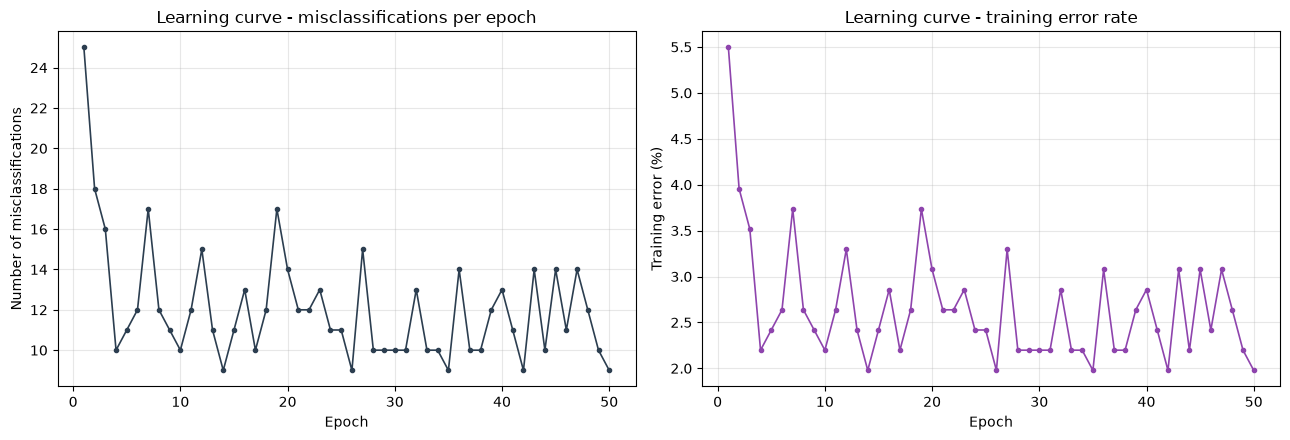

The error drops steeply in the first few epochs, then oscillates instead
of settling at zero. That oscillation is expected: this dataset is not
perfectly linearly separable, so some samples stay misclassified and keep
nudging the weights back and forth.


In [11]:
# Zain Ul Wahaj | FA23-BAI-058 | Task 3 (b)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

epochs_axis = range(1, EPOCHS + 1)

axes[0].plot(epochs_axis, baseline.errors_, marker="o", markersize=3,
             color="#2c3e50", linewidth=1.2)
axes[0].set_title("Learning curve - misclassifications per epoch")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Number of misclassifications")
axes[0].grid(alpha=0.3)

axes[1].plot(epochs_axis, np.array(baseline.error_rate_) * 100, marker="o",
             markersize=3, color="#8e44ad", linewidth=1.2)
axes[1].set_title("Learning curve - training error rate")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Training error (%)")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

print("The error drops steeply in the first few epochs, then oscillates instead")
print("of settling at zero. That oscillation is expected: this dataset is not")
print("perfectly linearly separable, so some samples stay misclassified and keep")
print("nudging the weights back and forth.")

### Task 3 (c)

> Display the final values of the weights and bias after training.

Final bias: -0.080000

Final weights, sorted by how strongly they influence the decision:

FEATURE                         WEIGHT
--------------------------------------
mean concavity                -0.19000
area error                    -0.18022
worst concavity               -0.17849
worst texture                 -0.17775
radius error                  -0.17060
mean compactness               0.16739
fractal dimension error        0.15814
mean concave points           -0.14437
concavity error                0.14351
worst area                    -0.13773

Weight vector length (L2 norm): 0.57525
Largest positive weight : 0.16739  -> pushes towards benign
Largest negative weight : -0.19000  -> pushes towards malignant


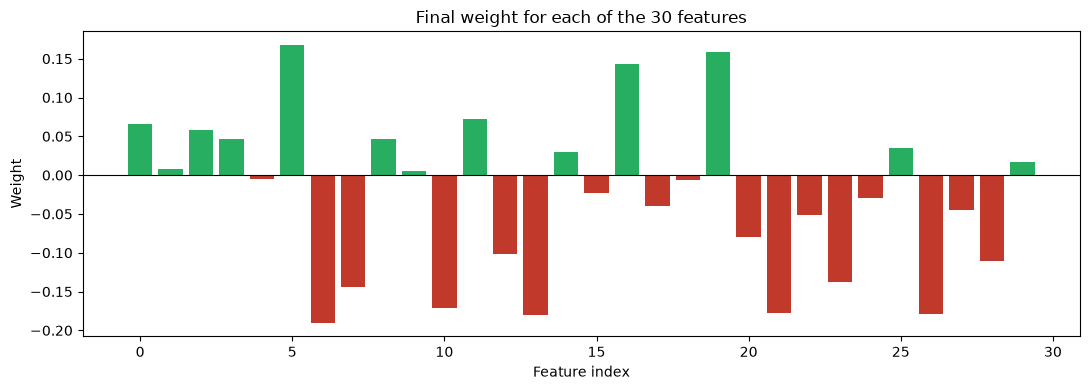

In [12]:
# Zain Ul Wahaj | FA23-BAI-058 | Task 3 (c)
print(f"Final bias: {baseline.b:.6f}\n")
print("Final weights, sorted by how strongly they influence the decision:\n")
print(f"{'FEATURE':<26}{'WEIGHT':>12}")
print("-" * 38)

order = np.argsort(np.abs(baseline.w))[::-1]
for idx in order[:10]:
    print(f"{data.feature_names[idx]:<26}{baseline.w[idx]:>12.5f}")

print(f"\nWeight vector length (L2 norm): {np.linalg.norm(baseline.w):.5f}")
print(f"Largest positive weight : {baseline.w.max():.5f}  -> pushes towards benign")
print(f"Largest negative weight : {baseline.w.min():.5f}  -> pushes towards malignant")

plt.figure(figsize=(11, 4))
colours = ["#27ae60" if v >= 0 else "#c0392b" for v in baseline.w]
plt.bar(range(len(baseline.w)), baseline.w, color=colours)
plt.axhline(0, color="black", linewidth=0.8)
plt.title("Final weight for each of the 30 features")
plt.xlabel("Feature index")
plt.ylabel("Weight")
plt.tight_layout()
plt.show()

### Task 3 (d)

> Visualize the final decision boundary, where applicable, and explain how it separates the two classes.

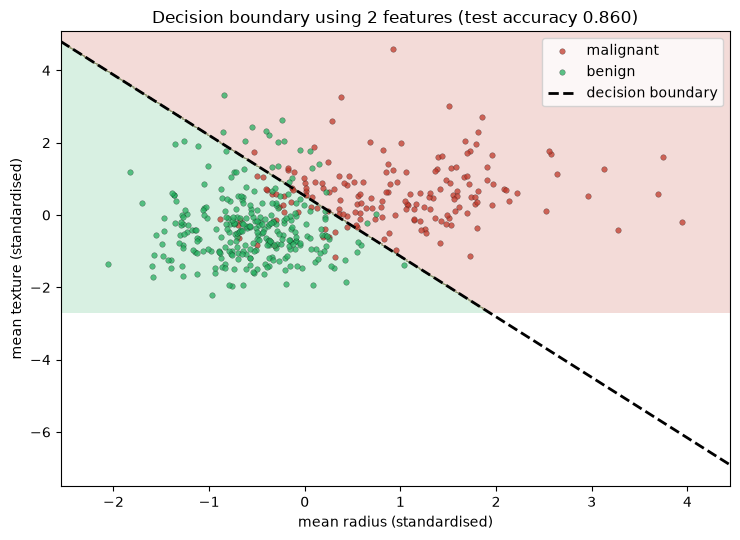

HOW THE BOUNDARY SEPARATES THE CLASSES
--------------------------------------
The perceptron computes z = w1*x1 + w2*x2 + b, with
   w1 = -0.0315, w2 = -0.0188, b = 0.0100
It predicts benign when z >= 0 and malignant when z < 0, so the dividing
line is exactly where z = 0. Because z is a weighted sum of the inputs,
that set of points is always a straight line (a hyperplane in higher
dimensions). The weight vector points perpendicular to the line, and the
bias shifts it away from the origin.

Points on the wrong side are the errors the perceptron cannot fix: a single
straight line simply cannot carve these two overlapping clouds apart.


In [13]:
# Zain Ul Wahaj | FA23-BAI-058 | Task 3 (d)
# The full model lives in 30 dimensions, which cannot be drawn. So we train the
# SAME perceptron on just two features to get a boundary we can actually see.
f1, f2 = 0, 1                    # mean radius, mean texture
X_train_2d = X_train[:, [f1, f2]]
X_test_2d = X_test[:, [f1, f2]]

model_2d = Perceptron(2, init="zeros", lr=LR, epochs=EPOCHS).fit(X_train_2d, y_train)
acc_2d = model_2d.score(X_test_2d, y_test)

# Evaluate the model across a grid to draw the boundary
xx, yy = np.meshgrid(
    np.linspace(X_train_2d[:, 0].min() - 0.5, X_train_2d[:, 0].max() + 0.5, 300),
    np.linspace(X_train_2d[:, 1].min() - 0.5, X_train_2d[:, 1].max() + 0.5, 300),
)
grid_pred = model_2d.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)

plt.figure(figsize=(7.5, 5.5))
plt.contourf(xx, yy, grid_pred, alpha=0.18, colors=["#c0392b", "#27ae60"])
for cls, colour, label in [(-1, "#c0392b", "malignant"), (1, "#27ae60", "benign")]:
    mask = y_train == cls
    plt.scatter(X_train_2d[mask, 0], X_train_2d[mask, 1], s=16, alpha=0.75,
                color=colour, edgecolor="k", linewidth=0.2, label=label)

# The boundary itself is the line w1*x1 + w2*x2 + b = 0
x_line = np.array([X_train_2d[:, 0].min() - 0.5, X_train_2d[:, 0].max() + 0.5])
y_line = -(model_2d.w[0] * x_line + model_2d.b) / model_2d.w[1]
plt.plot(x_line, y_line, "k--", linewidth=2, label="decision boundary")

plt.xlabel(f"{data.feature_names[f1]} (standardised)")
plt.ylabel(f"{data.feature_names[f2]} (standardised)")
plt.title(f"Decision boundary using 2 features (test accuracy {acc_2d:.3f})")
plt.legend()
plt.tight_layout()
plt.show()

print("HOW THE BOUNDARY SEPARATES THE CLASSES")
print("--------------------------------------")
print(f"The perceptron computes z = w1*x1 + w2*x2 + b, with")
print(f"   w1 = {model_2d.w[0]:.4f}, w2 = {model_2d.w[1]:.4f}, b = {model_2d.b:.4f}")
print("It predicts benign when z >= 0 and malignant when z < 0, so the dividing")
print("line is exactly where z = 0. Because z is a weighted sum of the inputs,")
print("that set of points is always a straight line (a hyperplane in higher")
print("dimensions). The weight vector points perpendicular to the line, and the")
print("bias shifts it away from the origin.")
print("\nPoints on the wrong side are the errors the perceptron cannot fix: a single")
print("straight line simply cannot carve these two overlapping clouds apart.")

---

## Task 4: Gaussian Weight Initialization

**Topic:** Normal-distribution initialisation and convergence

### Task 4 (a)

> Re-initialize the perceptron's weights using Gaussian/Normal initialization with a suitable mean and standard deviation.

In [14]:
# Zain Ul Wahaj | FA23-BAI-058 | Task 4 (a)
MEAN, STD = 0.0, 0.01

gaussian_model = Perceptron(n_features, init="gaussian", lr=LR,
                            epochs=EPOCHS, seed=SEED, std=STD)

print(f"Gaussian initialisation: mean = {MEAN}, std = {STD}")
print(f"\nInitial weights (first 8): {np.round(gaussian_model.w_initial[:8], 5)}")
print(f"Actual mean of the drawn weights : {gaussian_model.w_initial.mean():.6f}")
print(f"Actual std  of the drawn weights : {gaussian_model.w_initial.std():.6f}")
print(f"L2 norm of the weight vector     : {np.linalg.norm(gaussian_model.w_initial):.6f}")

print("\nA small std keeps the starting weights close to zero, so the first")
print("predictions are near the decision boundary and every sample can still")
print("influence the direction the weights move in.")

Gaussian initialisation: mean = 0.0, std = 0.01

Initial weights (first 8): [-0.00575  0.00092 -0.02112 -0.01397 -0.00757 -0.00222  0.00738  0.00112]
Actual mean of the drawn weights : -0.002928
Actual std  of the drawn weights : 0.008030
L2 norm of the weight vector     : 0.046813

A small std keeps the starting weights close to zero, so the first
predictions are near the decision boundary and every sample can still
influence the direction the weights move in.


### Task 4 (b)

> Train the perceptron using the same dataset, hyperparameters, and training procedure used previously.

In [15]:
# Zain Ul Wahaj | FA23-BAI-058 | Task 4 (b)
gaussian_model.fit(X_train, y_train)

print(f"Same settings as before: lr = {LR}, epochs = {EPOCHS}, seed = {SEED}")
print(f"Same data: {X_train.shape[0]} training samples, {X_test.shape[0]} test samples\n")

print("Errors per epoch (first 15):", gaussian_model.errors_[:15])
print("Errors per epoch (last 5)  :", gaussian_model.errors_[-5:])

print(f"\nTraining accuracy: {gaussian_model.score(X_train, y_train):.4f}")
print(f"Test accuracy    : {gaussian_model.score(X_test, y_test):.4f}")

Same settings as before: lr = 0.01, epochs = 50, seed = 58
Same data: 455 training samples, 114 test samples

Errors per epoch (first 15): [18, 17, 12, 8, 9, 15, 12, 11, 10, 17, 12, 17, 10, 14, 13]
Errors per epoch (last 5)  : [9, 10, 11, 15, 13]

Training accuracy: 0.9846
Test accuracy    : 0.9211


### Task 4 (c)

> Record the number of epochs required for the perceptron to converge and plot its learning curve.

CONVERGENCE
   Epochs to zero training error : never reached
   Epochs to <= 3% training error: 3
   Lowest error count            : 8 (epoch 4)

Note: the perceptron convergence theorem only promises zero error when the
data is linearly separable. This dataset is not, so we also track a practical
3% threshold and use that for comparing the initialisation strategies.


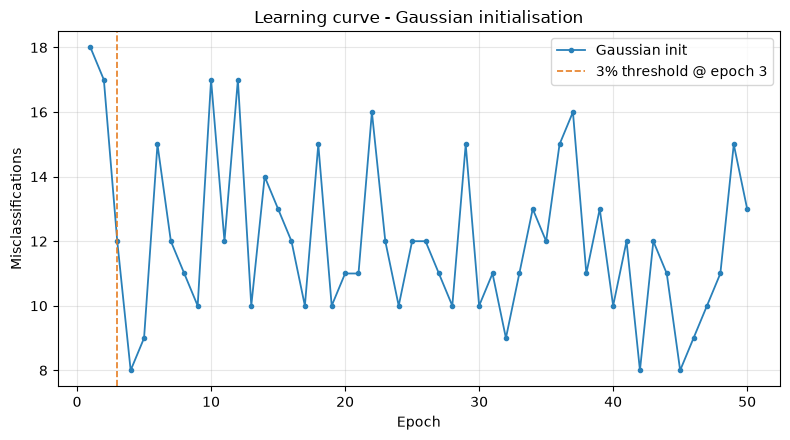

In [16]:
# Zain Ul Wahaj | FA23-BAI-058 | Task 4 (c)
zero_epoch = gaussian_model.epochs_to_zero_error()
thresh_epoch = gaussian_model.epochs_to_threshold(0.03)

print("CONVERGENCE")
print(f"   Epochs to zero training error : {zero_epoch if zero_epoch else 'never reached'}")
print(f"   Epochs to <= 3% training error: {thresh_epoch if thresh_epoch else 'never reached'}")
print(f"   Lowest error count            : {min(gaussian_model.errors_)}"
      f" (epoch {gaussian_model.errors_.index(min(gaussian_model.errors_)) + 1})")

print("\nNote: the perceptron convergence theorem only promises zero error when the")
print("data is linearly separable. This dataset is not, so we also track a practical")
print("3% threshold and use that for comparing the initialisation strategies.")

plt.figure(figsize=(8, 4.5))
plt.plot(range(1, EPOCHS + 1), gaussian_model.errors_, marker="o", markersize=3,
         color="#2980b9", linewidth=1.3, label="Gaussian init")
if thresh_epoch:
    plt.axvline(thresh_epoch, color="#e67e22", linestyle="--", linewidth=1.2,
                label=f"3% threshold @ epoch {thresh_epoch}")
plt.title("Learning curve - Gaussian initialisation")
plt.xlabel("Epoch")
plt.ylabel("Misclassifications")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Task 4 (d)

> Compare the Gaussian-initialized model with the default/randomly initialized model in terms of convergence and final weights.

                         ZEROS (default)      GAUSSIAN
------------------------------------------------------
First-epoch errors                    25            18
Final-epoch errors                     9            13
Lowest errors                          9             8
Epochs to <=3%                         4             3
Test accuracy                     0.9298        0.9211
Final |w| (L2 norm)               0.5753        0.5772
Final bias                       -0.0800       -0.0800

Cosine similarity between the two final weight vectors: 0.9860


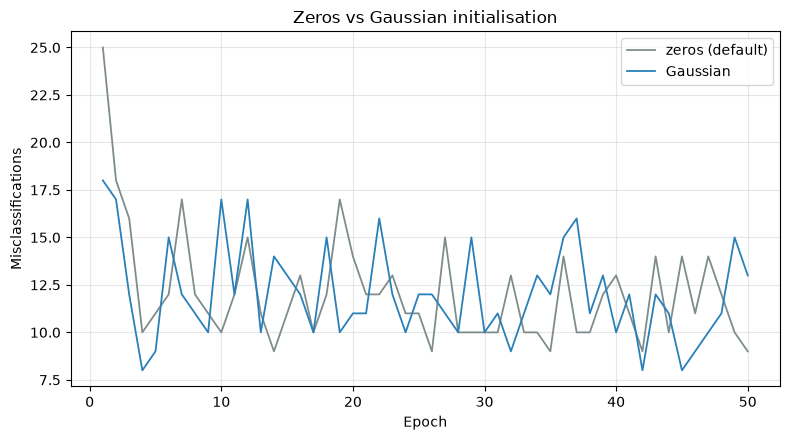

Because the Gaussian weights start very close to zero (std = 0.01), the two
runs follow almost the same path and end up pointing in nearly the same
direction - the high cosine similarity above confirms it.


In [17]:
# Zain Ul Wahaj | FA23-BAI-058 | Task 4 (d)
print(f"{'':<22}{'ZEROS (default)':>18}{'GAUSSIAN':>14}")
print("-" * 54)
print(f"{'First-epoch errors':<22}{baseline.errors_[0]:>18}{gaussian_model.errors_[0]:>14}")
print(f"{'Final-epoch errors':<22}{baseline.errors_[-1]:>18}{gaussian_model.errors_[-1]:>14}")
print(f"{'Lowest errors':<22}{min(baseline.errors_):>18}{min(gaussian_model.errors_):>14}")
print(f"{'Epochs to <=3%':<22}"
      f"{str(baseline.epochs_to_threshold(0.03)):>18}{str(gaussian_model.epochs_to_threshold(0.03)):>14}")
print(f"{'Test accuracy':<22}{baseline.score(X_test, y_test):>18.4f}{gaussian_model.score(X_test, y_test):>14.4f}")
print(f"{'Final |w| (L2 norm)':<22}{np.linalg.norm(baseline.w):>18.4f}{np.linalg.norm(gaussian_model.w):>14.4f}")
print(f"{'Final bias':<22}{baseline.b:>18.4f}{gaussian_model.b:>14.4f}")

similarity = float(np.dot(baseline.w, gaussian_model.w) /
                   (np.linalg.norm(baseline.w) * np.linalg.norm(gaussian_model.w)))
print(f"\nCosine similarity between the two final weight vectors: {similarity:.4f}")

plt.figure(figsize=(8, 4.5))
plt.plot(range(1, EPOCHS + 1), baseline.errors_, label="zeros (default)",
         color="#7f8c8d", linewidth=1.3)
plt.plot(range(1, EPOCHS + 1), gaussian_model.errors_, label="Gaussian",
         color="#2980b9", linewidth=1.3)
plt.title("Zeros vs Gaussian initialisation")
plt.xlabel("Epoch")
plt.ylabel("Misclassifications")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("Because the Gaussian weights start very close to zero (std = 0.01), the two")
print("runs follow almost the same path and end up pointing in nearly the same")
print("direction - the high cosine similarity above confirms it.")

---

## Task 5: Xavier/Glorot Initialization

**Topic:** Xavier initialisation and its effect on training

### Task 5 (a)

> Implement Xavier/Glorot initialization for the perceptron's weights.

In [18]:
# Zain Ul Wahaj | FA23-BAI-058 | Task 5 (a)
# Xavier/Glorot draws weights with variance 2 / (fan_in + fan_out).
# A perceptron has fan_in = number of features and fan_out = 1.
fan_in, fan_out = n_features, 1
xavier_std = np.sqrt(2.0 / (fan_in + fan_out))

xavier_model = Perceptron(n_features, init="xavier", lr=LR, epochs=EPOCHS, seed=SEED)

print(f"fan_in = {fan_in}, fan_out = {fan_out}")
print(f"Xavier std = sqrt(2 / ({fan_in} + {fan_out})) = {xavier_std:.6f}")
print(f"\nInitial weights (first 8): {np.round(xavier_model.w_initial[:8], 5)}")
print(f"Empirical std of weights : {xavier_model.w_initial.std():.6f}")
print(f"L2 norm                  : {np.linalg.norm(xavier_model.w_initial):.6f}")

print(f"\nCompared with Gaussian (std {STD}), Xavier starts about "
      f"{xavier_std / STD:.0f}x larger.")
print("The idea behind Xavier is to keep the variance of the signal roughly")
print("constant as it passes through a layer, so activations neither shrink")
print("away nor blow up.")

fan_in = 30, fan_out = 1
Xavier std = sqrt(2 / (30 + 1)) = 0.254000

Initial weights (first 8): [-0.14607  0.02338 -0.53639 -0.35485 -0.19216 -0.05645  0.18741  0.02857]
Empirical std of weights : 0.203958
L2 norm                  : 1.189063

Compared with Gaussian (std 0.01), Xavier starts about 25x larger.
The idea behind Xavier is to keep the variance of the signal roughly
constant as it passes through a layer, so activations neither shrink
away nor blow up.


### Task 5 (b)

> Train the perceptron using Xavier-initialized weights while keeping the dataset and training settings unchanged.

In [19]:
# Zain Ul Wahaj | FA23-BAI-058 | Task 5 (b)
xavier_model.fit(X_train, y_train)

print(f"Unchanged settings: lr = {LR}, epochs = {EPOCHS}, seed = {SEED}\n")
print("Errors per epoch (first 15):", xavier_model.errors_[:15])
print("Errors per epoch (last 5)  :", xavier_model.errors_[-5:])

print(f"\nTraining accuracy: {xavier_model.score(X_train, y_train):.4f}")
print(f"Test accuracy    : {xavier_model.score(X_test, y_test):.4f}")

Unchanged settings: lr = 0.01, epochs = 50, seed = 58

Errors per epoch (first 15): [30, 17, 14, 14, 13, 15, 10, 13, 11, 13, 12, 11, 13, 9, 12]
Errors per epoch (last 5)  : [6, 9, 13, 8, 9]

Training accuracy: 0.9868
Test accuracy    : 0.9211


### Task 5 (c)

> Record the number of epochs required for convergence and plot the corresponding learning curve.

CONVERGENCE - Xavier
   Epochs to zero error  : never reached
   Epochs to <= 3% error : 5
   Lowest error count    : 5 (epoch 34)


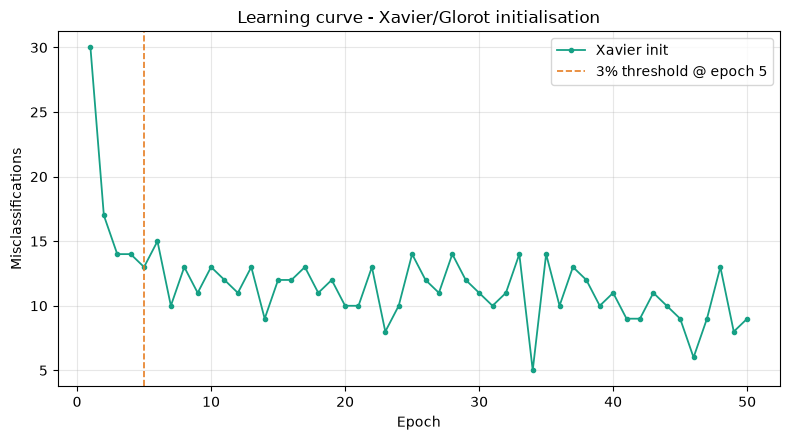

In [20]:
# Zain Ul Wahaj | FA23-BAI-058 | Task 5 (c)
x_zero = xavier_model.epochs_to_zero_error()
x_thresh = xavier_model.epochs_to_threshold(0.03)

print("CONVERGENCE - Xavier")
print(f"   Epochs to zero error  : {x_zero if x_zero else 'never reached'}")
print(f"   Epochs to <= 3% error : {x_thresh if x_thresh else 'never reached'}")
print(f"   Lowest error count    : {min(xavier_model.errors_)}"
      f" (epoch {xavier_model.errors_.index(min(xavier_model.errors_)) + 1})")

plt.figure(figsize=(8, 4.5))
plt.plot(range(1, EPOCHS + 1), xavier_model.errors_, marker="o", markersize=3,
         color="#16a085", linewidth=1.3, label="Xavier init")
if x_thresh:
    plt.axvline(x_thresh, color="#e67e22", linestyle="--", linewidth=1.2,
                label=f"3% threshold @ epoch {x_thresh}")
plt.title("Learning curve - Xavier/Glorot initialisation")
plt.xlabel("Epoch")
plt.ylabel("Misclassifications")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Task 5 (d)

> Compare the results with Gaussian initialization and discuss how the initialization affected the training process.

                            GAUSSIAN      XAVIER
------------------------------------------------
Starting |w|                  0.0468      1.1891
First-epoch errors                18          30
Final-epoch errors                13           9
Lowest errors                      8           5
Epochs to <=3%                     3           5
Test accuracy                 0.9211      0.9211
Final |w|                     0.5772      0.9998


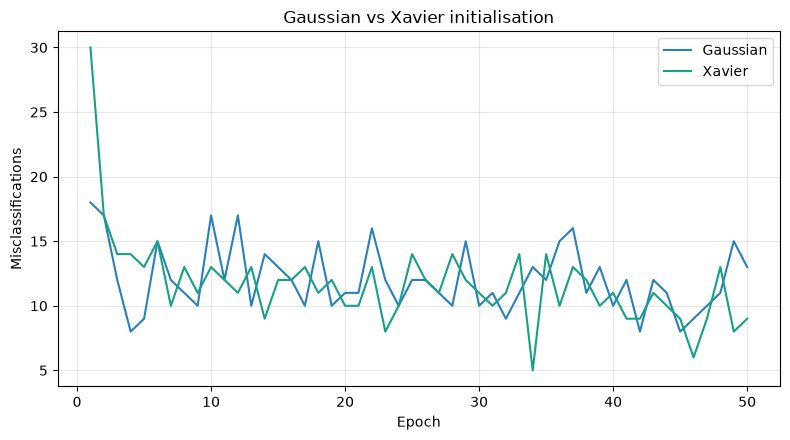

HOW THE INITIALISATION AFFECTED TRAINING
----------------------------------------
The starting weight vector is much longer under Xavier. With a fixed learning
rate, each update changes the weights by the same small amount either way, so
a longer starting vector takes proportionally more updates before the direction
of w is dominated by the data rather than by its random starting point.

That is why Xavier usually needs more epochs early on. For a single perceptron
the effect is modest, because there is only one layer and no signal being
passed through repeated multiplications - which is the problem Xavier was
actually designed to solve in deep networks.


In [21]:
# Zain Ul Wahaj | FA23-BAI-058 | Task 5 (d)
print(f"{'':<24}{'GAUSSIAN':>12}{'XAVIER':>12}")
print("-" * 48)
print(f"{'Starting |w|':<24}{np.linalg.norm(gaussian_model.w_initial):>12.4f}"
      f"{np.linalg.norm(xavier_model.w_initial):>12.4f}")
print(f"{'First-epoch errors':<24}{gaussian_model.errors_[0]:>12}{xavier_model.errors_[0]:>12}")
print(f"{'Final-epoch errors':<24}{gaussian_model.errors_[-1]:>12}{xavier_model.errors_[-1]:>12}")
print(f"{'Lowest errors':<24}{min(gaussian_model.errors_):>12}{min(xavier_model.errors_):>12}")
print(f"{'Epochs to <=3%':<24}{str(gaussian_model.epochs_to_threshold(0.03)):>12}"
      f"{str(xavier_model.epochs_to_threshold(0.03)):>12}")
print(f"{'Test accuracy':<24}{gaussian_model.score(X_test, y_test):>12.4f}"
      f"{xavier_model.score(X_test, y_test):>12.4f}")
print(f"{'Final |w|':<24}{np.linalg.norm(gaussian_model.w):>12.4f}"
      f"{np.linalg.norm(xavier_model.w):>12.4f}")

plt.figure(figsize=(8, 4.5))
plt.plot(range(1, EPOCHS + 1), gaussian_model.errors_, label="Gaussian", color="#2980b9")
plt.plot(range(1, EPOCHS + 1), xavier_model.errors_, label="Xavier", color="#16a085")
plt.title("Gaussian vs Xavier initialisation")
plt.xlabel("Epoch")
plt.ylabel("Misclassifications")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("HOW THE INITIALISATION AFFECTED TRAINING")
print("----------------------------------------")
print("The starting weight vector is much longer under Xavier. With a fixed learning")
print("rate, each update changes the weights by the same small amount either way, so")
print("a longer starting vector takes proportionally more updates before the direction")
print("of w is dominated by the data rather than by its random starting point.")
print("\nThat is why Xavier usually needs more epochs early on. For a single perceptron")
print("the effect is modest, because there is only one layer and no signal being")
print("passed through repeated multiplications - which is the problem Xavier was")
print("actually designed to solve in deep networks.")

---

## Task 6: He/Kaiming Initialization

**Topic:** He initialisation for ReLU-style networks

### Task 6 (a)

> Implement He/Kaiming initialization for the perceptron's weights.

In [22]:
# Zain Ul Wahaj | FA23-BAI-058 | Task 6 (a)
he_std = np.sqrt(2.0 / n_features)
he_model = Perceptron(n_features, init="he", lr=LR, epochs=EPOCHS, seed=SEED)

print(f"He/Kaiming std = sqrt(2 / fan_in) = sqrt(2 / {n_features}) = {he_std:.6f}")
print(f"\nInitial weights (first 8): {np.round(he_model.w_initial[:8], 5)}")
print(f"Empirical std : {he_model.w_initial.std():.6f}")
print(f"L2 norm       : {np.linalg.norm(he_model.w_initial):.6f}")

print(f"\nStarting scale comparison")
print(f"   Gaussian : {np.linalg.norm(gaussian_model.w_initial):.4f}")
print(f"   Xavier   : {np.linalg.norm(xavier_model.w_initial):.4f}")
print(f"   He       : {np.linalg.norm(he_model.w_initial):.4f}")
print("\nHe uses 2/fan_in rather than Xavier's 2/(fan_in+fan_out). It was designed")
print("for ReLU activations, which zero out half their inputs, so the extra")
print("variance compensates for that lost signal.")

He/Kaiming std = sqrt(2 / fan_in) = sqrt(2 / 30) = 0.258199

Initial weights (first 8): [-0.14848  0.02377 -0.54526 -0.36072 -0.19534 -0.05739  0.19051  0.02904]
Empirical std : 0.207330
L2 norm       : 1.208718

Starting scale comparison
   Gaussian : 0.0468
   Xavier   : 1.1891
   He       : 1.2087

He uses 2/fan_in rather than Xavier's 2/(fan_in+fan_out). It was designed
for ReLU activations, which zero out half their inputs, so the extra
variance compensates for that lost signal.


### Task 6 (b)

> Train the perceptron using the He-initialized weights on the same training dataset.

In [23]:
# Zain Ul Wahaj | FA23-BAI-058 | Task 6 (b)
he_model.fit(X_train, y_train)

print(f"Unchanged settings: lr = {LR}, epochs = {EPOCHS}, seed = {SEED}\n")
print("Errors per epoch (first 15):", he_model.errors_[:15])
print("Errors per epoch (last 5)  :", he_model.errors_[-5:])
print(f"\nTraining accuracy: {he_model.score(X_train, y_train):.4f}")
print(f"Test accuracy    : {he_model.score(X_test, y_test):.4f}")

Unchanged settings: lr = 0.01, epochs = 50, seed = 58

Errors per epoch (first 15): [31, 15, 15, 14, 14, 13, 11, 11, 14, 11, 14, 14, 11, 12, 12]
Errors per epoch (last 5)  : [11, 10, 7, 11, 4]

Training accuracy: 0.9824
Test accuracy    : 0.9298


### Task 6 (c)

> Record the convergence behavior, number of epochs, final weights, and test accuracy.

CONVERGENCE - He/Kaiming
   Epochs to zero error  : never reached
   Epochs to <= 3% error : 6
   Lowest error count    : 4 (epoch 50)
   Test accuracy         : 0.9298

Final bias: -0.080000
Final |w| : 1.009036

Top 5 features by absolute weight:
   worst perimeter              0.38810
   worst concavity             -0.35273
   perimeter error             -0.31177
   worst concave points        -0.30546
   worst area                  -0.27923


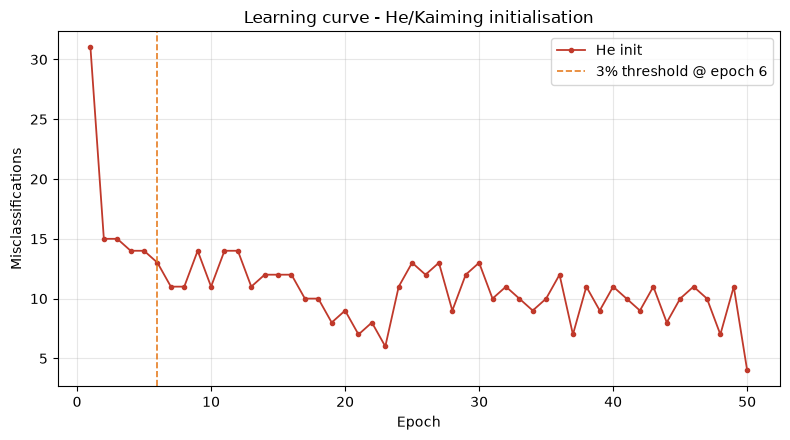

In [24]:
# Zain Ul Wahaj | FA23-BAI-058 | Task 6 (c)
h_zero = he_model.epochs_to_zero_error()
h_thresh = he_model.epochs_to_threshold(0.03)

print("CONVERGENCE - He/Kaiming")
print(f"   Epochs to zero error  : {h_zero if h_zero else 'never reached'}")
print(f"   Epochs to <= 3% error : {h_thresh if h_thresh else 'never reached'}")
print(f"   Lowest error count    : {min(he_model.errors_)}"
      f" (epoch {he_model.errors_.index(min(he_model.errors_)) + 1})")
print(f"   Test accuracy         : {he_model.score(X_test, y_test):.4f}")

print(f"\nFinal bias: {he_model.b:.6f}")
print(f"Final |w| : {np.linalg.norm(he_model.w):.6f}")
print("\nTop 5 features by absolute weight:")
for idx in np.argsort(np.abs(he_model.w))[::-1][:5]:
    print(f"   {data.feature_names[idx]:<26}{he_model.w[idx]:>10.5f}")

plt.figure(figsize=(8, 4.5))
plt.plot(range(1, EPOCHS + 1), he_model.errors_, marker="o", markersize=3,
         color="#c0392b", linewidth=1.3, label="He init")
if h_thresh:
    plt.axvline(h_thresh, color="#e67e22", linestyle="--", linewidth=1.2,
                label=f"3% threshold @ epoch {h_thresh}")
plt.title("Learning curve - He/Kaiming initialisation")
plt.xlabel("Epoch")
plt.ylabel("Misclassifications")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Task 6 (d)

> Compare the He initialization results with Gaussian and Xavier initialization.

METRIC                    Gaussian      Xavier          He
----------------------------------------------------------
Starting |w|                0.0468      1.1891      1.2087
First-epoch errors              18          30          31
Final-epoch errors              13           9           4
Lowest errors                    8           5           4
Epochs to <=3%                   3           5           6
Test accuracy               0.9211      0.9211      0.9298
Final |w|                   0.5772      0.9998      1.0090


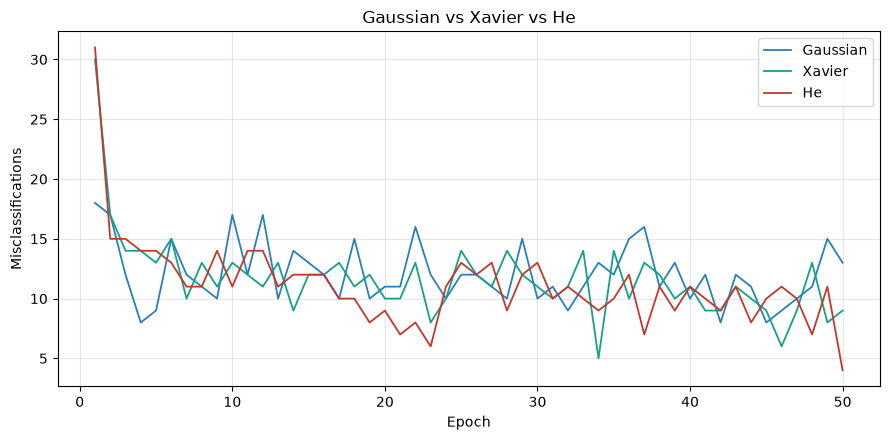

He starts with the largest weights of the three, so its first epoch makes the
most mistakes. All three end up at a similar error level, which tells us the
initialisation mainly changes the EARLY part of training here rather than
where the model finally lands.


In [25]:
# Zain Ul Wahaj | FA23-BAI-058 | Task 6 (d)
models_so_far = [("Gaussian", gaussian_model), ("Xavier", xavier_model), ("He", he_model)]

print(f"{'METRIC':<22}" + "".join(f"{name:>12}" for name, _ in models_so_far))
print("-" * (22 + 12 * len(models_so_far)))

rows = [
    ("Starting |w|", lambda m: f"{np.linalg.norm(m.w_initial):.4f}"),
    ("First-epoch errors", lambda m: str(m.errors_[0])),
    ("Final-epoch errors", lambda m: str(m.errors_[-1])),
    ("Lowest errors", lambda m: str(min(m.errors_))),
    ("Epochs to <=3%", lambda m: str(m.epochs_to_threshold(0.03))),
    ("Test accuracy", lambda m: f"{m.score(X_test, y_test):.4f}"),
    ("Final |w|", lambda m: f"{np.linalg.norm(m.w):.4f}"),
]
for label, fn in rows:
    print(f"{label:<22}" + "".join(f"{fn(m):>12}" for _, m in models_so_far))

plt.figure(figsize=(9, 4.5))
for (name, m), colour in zip(models_so_far, ["#2980b9", "#16a085", "#c0392b"]):
    plt.plot(range(1, EPOCHS + 1), m.errors_, label=name, color=colour, linewidth=1.3)
plt.title("Gaussian vs Xavier vs He")
plt.xlabel("Epoch")
plt.ylabel("Misclassifications")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("He starts with the largest weights of the three, so its first epoch makes the")
print("most mistakes. All three end up at a similar error level, which tells us the")
print("initialisation mainly changes the EARLY part of training here rather than")
print("where the model finally lands.")

---

## Task 7: Orthogonal Initialization

**Topic:** Orthogonal initialisation via QR decomposition

### Task 7 (a)

> Implement Orthogonal initialization for the perceptron's weight matrix.

In [26]:
# Zain Ul Wahaj | FA23-BAI-058 | Task 7 (a)
ortho_model = Perceptron(n_features, init="orthogonal", lr=LR, epochs=EPOCHS, seed=SEED)

print("Orthogonal initialisation is built by taking the QR decomposition of a")
print("random matrix and keeping Q, whose columns are orthonormal.\n")

print(f"Initial weights (first 8): {np.round(ortho_model.w_initial[:8], 5)}")
print(f"L2 norm of the weight vector: {np.linalg.norm(ortho_model.w_initial):.6f}")

print("\nIMPORTANT CAVEAT")
print("----------------")
print("Orthogonal initialisation is defined for weight MATRICES - it makes the rows")
print("(or columns) mutually perpendicular, which preserves vector lengths when a")
print("signal passes through the layer. A perceptron has a single output, so its")
print("'matrix' is one row of shape (1, 30). A single row cannot be orthogonal to")
print("anything, so the method collapses to a random vector of unit length, which")
print("is exactly what the norm of 1.0 above shows.")
print("\nThe technique only shows its real benefit in deep or recurrent networks with")
print("genuinely 2-D weight matrices.")

print(f"\nStarting scale of all four strategies")
for nm, m in [("Gaussian", gaussian_model), ("Xavier", xavier_model),
              ("He", he_model), ("Orthogonal", ortho_model)]:
    print(f"   {nm:<12}|w| = {np.linalg.norm(m.w_initial):.4f}")

Orthogonal initialisation is built by taking the QR decomposition of a
random matrix and keeping Q, whose columns are orthonormal.

Initial weights (first 8): [-0.12284  0.01967 -0.4511  -0.29843 -0.16161 -0.04748  0.15761  0.02403]
L2 norm of the weight vector: 1.000000

IMPORTANT CAVEAT
----------------
Orthogonal initialisation is defined for weight MATRICES - it makes the rows
(or columns) mutually perpendicular, which preserves vector lengths when a
signal passes through the layer. A perceptron has a single output, so its
'matrix' is one row of shape (1, 30). A single row cannot be orthogonal to
anything, so the method collapses to a random vector of unit length, which
is exactly what the norm of 1.0 above shows.

The technique only shows its real benefit in deep or recurrent networks with
genuinely 2-D weight matrices.

Starting scale of all four strategies
   Gaussian    |w| = 0.0468
   Xavier      |w| = 1.1891
   He          |w| = 1.2087
   Orthogonal  |w| = 1.0000


### Task 7 (b)

> Train the perceptron using the orthogonally initialized weights while keeping all other experimental settings consistent.

In [27]:
# Zain Ul Wahaj | FA23-BAI-058 | Task 7 (b)
ortho_model.fit(X_train, y_train)

print(f"Unchanged settings: lr = {LR}, epochs = {EPOCHS}, seed = {SEED}\n")
print("Errors per epoch (first 15):", ortho_model.errors_[:15])
print("Errors per epoch (last 5)  :", ortho_model.errors_[-5:])
print(f"\nTraining accuracy: {ortho_model.score(X_train, y_train):.4f}")
print(f"Test accuracy    : {ortho_model.score(X_test, y_test):.4f}")

Unchanged settings: lr = 0.01, epochs = 50, seed = 58



Errors per epoch (first 15): [29, 16, 14, 13, 13, 11, 10, 13, 12, 12, 13, 10, 8, 13, 14]
Errors per epoch (last 5)  : [8, 13, 8, 6, 6]

Training accuracy: 0.9846
Test accuracy    : 0.9298


### Task 7 (c)

> Plot the learning curve and record the number of epochs required for convergence.

CONVERGENCE - Orthogonal
   Epochs to zero error  : never reached
   Epochs to <= 3% error : 4
   Lowest error count    : 6 (epoch 33)


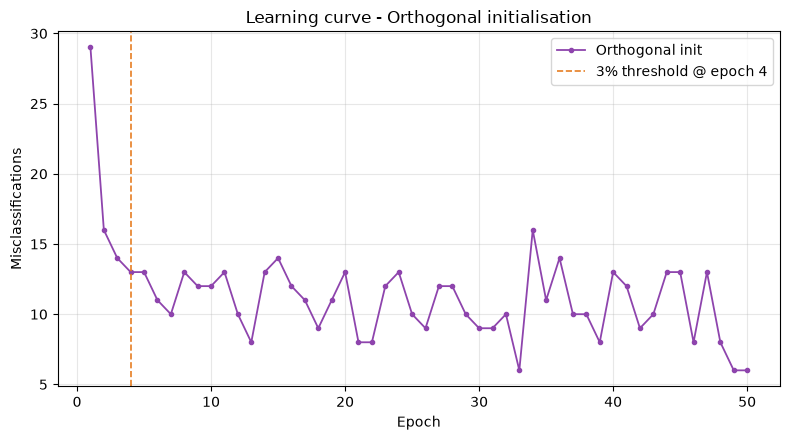

In [28]:
# Zain Ul Wahaj | FA23-BAI-058 | Task 7 (c)
o_zero = ortho_model.epochs_to_zero_error()
o_thresh = ortho_model.epochs_to_threshold(0.03)

print("CONVERGENCE - Orthogonal")
print(f"   Epochs to zero error  : {o_zero if o_zero else 'never reached'}")
print(f"   Epochs to <= 3% error : {o_thresh if o_thresh else 'never reached'}")
print(f"   Lowest error count    : {min(ortho_model.errors_)}"
      f" (epoch {ortho_model.errors_.index(min(ortho_model.errors_)) + 1})")

plt.figure(figsize=(8, 4.5))
plt.plot(range(1, EPOCHS + 1), ortho_model.errors_, marker="o", markersize=3,
         color="#8e44ad", linewidth=1.3, label="Orthogonal init")
if o_thresh:
    plt.axvline(o_thresh, color="#e67e22", linestyle="--", linewidth=1.2,
                label=f"3% threshold @ epoch {o_thresh}")
plt.title("Learning curve - Orthogonal initialisation")
plt.xlabel("Epoch")
plt.ylabel("Misclassifications")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Task 7 (d)

> Compare Orthogonal initialization with Gaussian, Xavier, and He initialization based on convergence behavior and final model parameters.

METRIC                     Gaussian       Xavier           He   Orthogonal
--------------------------------------------------------------------------
Starting |w|                 0.0468       1.1891       1.2087       1.0000
First-epoch errors               18           30           31           29
Final-epoch errors               13            9            4            6
Lowest errors                     8            5            4            6
Epochs to <=3%                    3            5            6            4
Test accuracy                0.9211       0.9211       0.9298       0.9298
Final |w|                    0.5772       0.9998       1.0090       0.8832
Final bias                  -0.0800      -0.0700      -0.0800      -0.0900


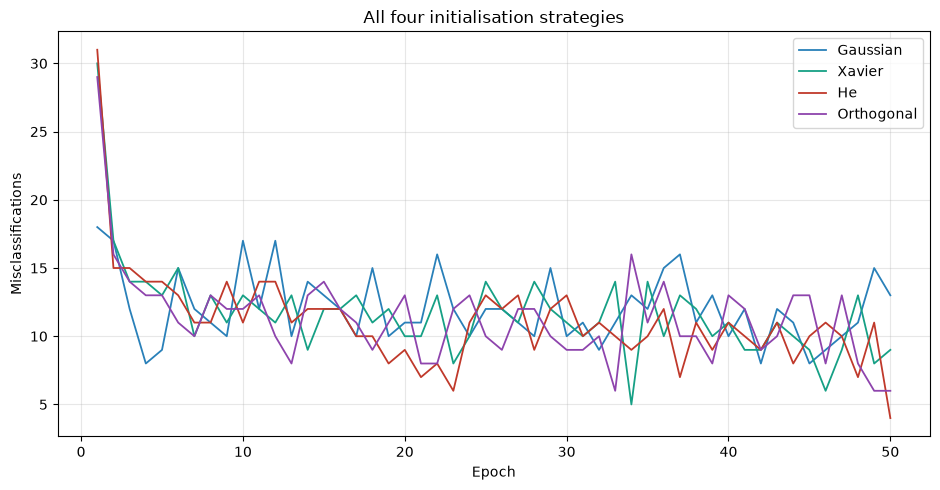

Orthogonal starts with |w| = 1 by construction, placing it between Xavier
and He in scale. Its curve sits in that same middle band, which supports the
reading that for a single perceptron it is the STARTING SCALE of the weights
that drives the differences, not the orthogonality property itself.


In [29]:
# Zain Ul Wahaj | FA23-BAI-058 | Task 7 (d)
all_models = [("Gaussian", gaussian_model), ("Xavier", xavier_model),
              ("He", he_model), ("Orthogonal", ortho_model)]

print(f"{'METRIC':<22}" + "".join(f"{n:>13}" for n, _ in all_models))
print("-" * (22 + 13 * len(all_models)))
for label, fn in [
    ("Starting |w|", lambda m: f"{np.linalg.norm(m.w_initial):.4f}"),
    ("First-epoch errors", lambda m: str(m.errors_[0])),
    ("Final-epoch errors", lambda m: str(m.errors_[-1])),
    ("Lowest errors", lambda m: str(min(m.errors_))),
    ("Epochs to <=3%", lambda m: str(m.epochs_to_threshold(0.03))),
    ("Test accuracy", lambda m: f"{m.score(X_test, y_test):.4f}"),
    ("Final |w|", lambda m: f"{np.linalg.norm(m.w):.4f}"),
    ("Final bias", lambda m: f"{m.b:.4f}"),
]:
    print(f"{label:<22}" + "".join(f"{fn(m):>13}" for _, m in all_models))

plt.figure(figsize=(9.5, 5))
for (name, m), colour in zip(all_models, ["#2980b9", "#16a085", "#c0392b", "#8e44ad"]):
    plt.plot(range(1, EPOCHS + 1), m.errors_, label=name, color=colour, linewidth=1.3)
plt.title("All four initialisation strategies")
plt.xlabel("Epoch")
plt.ylabel("Misclassifications")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("Orthogonal starts with |w| = 1 by construction, placing it between Xavier")
print("and He in scale. Its curve sits in that same middle band, which supports the")
print("reading that for a single perceptron it is the STARTING SCALE of the weights")
print("that drives the differences, not the orthogonality property itself.")

---

## Task 8: Comparative Analysis of Weight Initialization Techniques

**Topic:** Side-by-side comparison of all four strategies

### Task 8 (a)

> Train the same perceptron using Gaussian, Xavier, He, and Orthogonal initialization on the same dataset.

In [30]:
# Zain Ul Wahaj | FA23-BAI-058 | Task 8 (a)
STRATEGIES = ["gaussian", "xavier", "he", "orthogonal"]
trained = {}

for strategy in STRATEGIES:
    model = Perceptron(n_features, init=strategy, lr=LR, epochs=EPOCHS,
                       seed=SEED, std=STD)
    model.fit(X_train, y_train)
    trained[strategy] = model
    print(f"{strategy:<12} trained -> test accuracy {model.score(X_test, y_test):.4f}")

print(f"\nAll four used identical settings:")
print(f"   dataset : Breast Cancer Wisconsin, {X_train.shape[0]} train / {X_test.shape[0]} test")
print(f"   lr      : {LR}")
print(f"   epochs  : {EPOCHS}")
print(f"   seed    : {SEED}")
print("The ONLY difference between the runs is how the weights started.")

gaussian     trained -> test accuracy 0.9211
xavier       trained -> test accuracy 0.9211


he           trained -> test accuracy 0.9298


orthogonal   trained -> test accuracy 0.9298

All four used identical settings:
   dataset : Breast Cancer Wisconsin, 455 train / 114 test
   lr      : 0.01
   epochs  : 50
   seed    : 58
The ONLY difference between the runs is how the weights started.


### Task 8 (b)

> Record the number of epochs, final training error, test accuracy, and final weight values for each initialization technique.

In [31]:
# Zain Ul Wahaj | FA23-BAI-058 | Task 8 (b)
results = pd.DataFrame([
    {
        "Initialization": s.capitalize(),
        "Start |w|": round(float(np.linalg.norm(trained[s].w_initial)), 4),
        "Epochs to <=3%": trained[s].epochs_to_threshold(0.03),
        "Epochs to 0 err": trained[s].epochs_to_zero_error(),
        "Final train err": trained[s].errors_[-1],
        "Lowest err": min(trained[s].errors_),
        "Train acc": round(trained[s].score(X_train, y_train), 4),
        "Test acc": round(trained[s].score(X_test, y_test), 4),
        "Final |w|": round(float(np.linalg.norm(trained[s].w)), 4),
        "Final bias": round(float(trained[s].b), 4),
    }
    for s in STRATEGIES
])

print("COMPARISON TABLE")
print(results.to_string(index=False))

print("\nFirst 5 final weight values for each strategy:")
for s in STRATEGIES:
    print(f"   {s:<12}{np.round(trained[s].w[:5], 4)}")

print("\n'Epochs to 0 err' is None everywhere because this dataset is not linearly")
print("separable, so the perceptron never reaches a perfect training split.")

COMPARISON TABLE
Initialization  Start |w|  Epochs to <=3% Epochs to 0 err  Final train err  Lowest err  Train acc  Test acc  Final |w|  Final bias
      Gaussian     0.0468               3            None               13           8     0.9846    0.9211     0.5772       -0.08
        Xavier     1.1891               5            None                9           5     0.9868    0.9211     0.9998       -0.07
            He     1.2087               6            None                4           4     0.9824    0.9298     1.0090       -0.08
    Orthogonal     1.0000               4            None                6           6     0.9846    0.9298     0.8832       -0.09

First 5 final weight values for each strategy:
   gaussian    [ 0.0685 -0.0069  0.0401  0.042   0.0099]
   xavier      [ 0.1864 -0.0077 -0.2371 -0.0556  0.0203]
   he          [ 0.1948  0.0136 -0.238  -0.0584  0.0359]
   orthogonal  [ 0.1618  0.0017 -0.1986 -0.0449  0.0124]

'Epochs to 0 err' is None everywhere because this d

### Task 8 (c)

> Plot the learning curves of all initialization techniques and compare their convergence behavior.

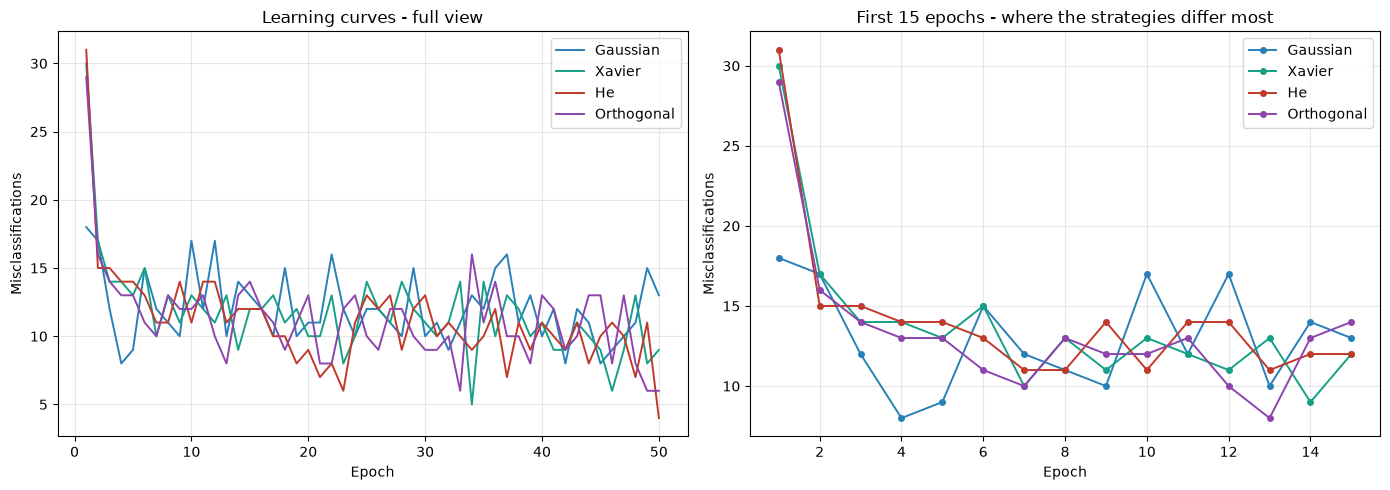

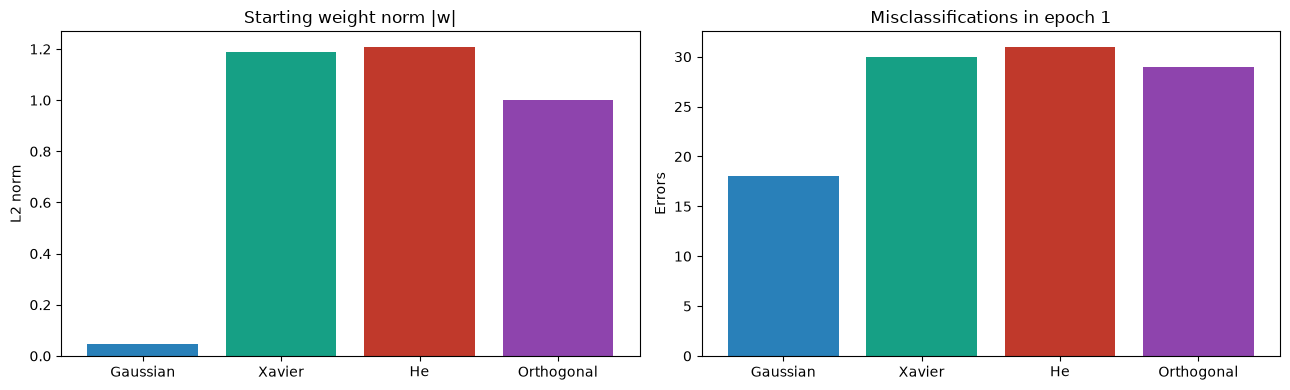

The two bar charts line up closely: the larger the starting weight vector,
the more mistakes the model makes in its first pass through the data.


In [32]:
# Zain Ul Wahaj | FA23-BAI-058 | Task 8 (c)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
colours = {"gaussian": "#2980b9", "xavier": "#16a085",
           "he": "#c0392b", "orthogonal": "#8e44ad"}

for s in STRATEGIES:
    axes[0].plot(range(1, EPOCHS + 1), trained[s].errors_,
                 label=s.capitalize(), color=colours[s], linewidth=1.4)
axes[0].set_title("Learning curves - full view")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Misclassifications")
axes[0].legend()
axes[0].grid(alpha=0.3)

for s in STRATEGIES:
    axes[1].plot(range(1, 16), trained[s].errors_[:15], marker="o", markersize=4,
                 label=s.capitalize(), color=colours[s], linewidth=1.4)
axes[1].set_title("First 15 epochs - where the strategies differ most")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Misclassifications")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

# Bar chart of starting scale against early error
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
names = [s.capitalize() for s in STRATEGIES]
axes[0].bar(names, [np.linalg.norm(trained[s].w_initial) for s in STRATEGIES],
            color=[colours[s] for s in STRATEGIES])
axes[0].set_title("Starting weight norm |w|")
axes[0].set_ylabel("L2 norm")

axes[1].bar(names, [trained[s].errors_[0] for s in STRATEGIES],
            color=[colours[s] for s in STRATEGIES])
axes[1].set_title("Misclassifications in epoch 1")
axes[1].set_ylabel("Errors")

plt.tight_layout()
plt.show()

print("The two bar charts line up closely: the larger the starting weight vector,")
print("the more mistakes the model makes in its first pass through the data.")

### Task 8 (d)

> Write a short analysis explaining why different initialization techniques may produce different training behavior.

In [33]:
# Zain Ul Wahaj | FA23-BAI-058 | Task 8 (d)
print("ANALYSIS - WHY INITIALISATION CHANGES TRAINING BEHAVIOUR")
print("=" * 60)

print("""
1. THE STARTING POINT DECIDES HOW FAR THERE IS TO TRAVEL
   The perceptron update w <- w + lr * y * x always moves the weight vector by a
   fixed step size. If the weights begin near zero, the very first few updates
   already dominate the direction of w, and the model is effectively learning
   straight from the data. If they begin large, those same small steps must first
   overcome the random starting vector before the data has any real influence.
   That is the single biggest effect visible in this lab, and it explains why the
   starting-norm bar chart and the epoch-1 error bar chart have the same shape.

2. INITIALISATION SETS THE SCALE OF THE DECISION BOUNDARY
   Predictions depend on the SIGN of w.x + b, not its magnitude. Scaling w by a
   constant leaves every prediction unchanged. So what matters is not the size of
   the weights on their own, but their size RELATIVE to the learning-rate step.
   A large |w| with a small lr behaves like a small lr; that is why He, with the
   largest starting norm here, looks the slowest to settle.

3. THE METHODS WERE DESIGNED FOR DEEP NETWORKS, NOT THIS ONE
   Xavier keeps signal variance stable across many layers. He corrects for ReLU
   discarding half its input. Orthogonal preserves vector lengths through repeated
   matrix multiplications, which matters in deep and recurrent stacks. A perceptron
   has ONE layer, a step activation and no gradients flowing backwards, so none of
   those mechanisms can actually engage. What survives is only their side effect:
   a different starting scale.

4. SYMMETRY BREAKING DOES NOT MATTER HERE, THOUGH IT USUALLY DOES
   In a multi-neuron layer, initialising every weight to zero is fatal - all the
   neurons compute the same thing and receive the same updates, so they never
   become different from one another. Random initialisation is what breaks that
   symmetry. A perceptron has a single neuron with nothing to be symmetric with,
   which is why the plain zeros baseline in Task 3 trains perfectly well.

5. THE DATA MATTERS MORE THAN THE INITIALISATION
   Every strategy landed at a similar final error and test accuracy. The ceiling
   here is set by the dataset, not the starting weights: the two classes overlap,
   so no straight line can separate them and the error oscillates permanently
   instead of reaching zero. Initialisation changed how quickly each run got to
   that ceiling, not where the ceiling was.
""")

best = max(STRATEGIES, key=lambda s: trained[s].score(X_test, y_test))
spread = (max(trained[s].score(X_test, y_test) for s in STRATEGIES) -
          min(trained[s].score(X_test, y_test) for s in STRATEGIES))
print(f"Best test accuracy in this single run: {best} "
      f"({trained[best].score(X_test, y_test):.4f})")
print(f"Spread between best and worst        : {spread:.4f}")
print("\nThat spread is small enough that a single run cannot settle which method is")
print("better - which is exactly what Task 9 tests by repeating with several seeds.")

ANALYSIS - WHY INITIALISATION CHANGES TRAINING BEHAVIOUR

1. THE STARTING POINT DECIDES HOW FAR THERE IS TO TRAVEL
   The perceptron update w <- w + lr * y * x always moves the weight vector by a
   fixed step size. If the weights begin near zero, the very first few updates
   already dominate the direction of w, and the model is effectively learning
   straight from the data. If they begin large, those same small steps must first
   overcome the random starting vector before the data has any real influence.
   That is the single biggest effect visible in this lab, and it explains why the
   starting-norm bar chart and the epoch-1 error bar chart have the same shape.

2. INITIALISATION SETS THE SCALE OF THE DECISION BOUNDARY
   Predictions depend on the SIGN of w.x + b, not its magnitude. Scaling w by a
   constant leaves every prediction unchanged. So what matters is not the size of
   the weights on their own, but their size RELATIVE to the learning-rate step.
   A large |w| with a s

---

## Task 9: Experimental Study and Interpretation

**Topic:** Second dataset, repeated runs across random seeds

### Task 9 (a)

> Select a different suitable binary-classification dataset and repeat the perceptron experiment using Gaussian, Xavier, He, and Orthogonal initialization.

In [34]:
# Zain Ul Wahaj | FA23-BAI-058 | Task 9 (a)
from sklearn.datasets import load_wine

# Wine dataset (UCI). It has 3 cultivars, so we turn it into a binary problem:
# cultivar 0 against the other two.
wine = load_wine()
Xw = wine.data
yw = np.where(wine.target == 0, 1, -1)

Xw_train_raw, Xw_test_raw, yw_train, yw_test = train_test_split(
    Xw, yw, test_size=0.2, random_state=SEED, stratify=yw
)
wine_scaler = StandardScaler().fit(Xw_train_raw)
Xw_train = wine_scaler.transform(Xw_train_raw)
Xw_test = wine_scaler.transform(Xw_test_raw)

print("Dataset 2: Wine (UCI ML Repository)")
print(f"   Samples  : {Xw.shape[0]}")
print(f"   Features : {Xw.shape[1]}")
print(f"   Task     : cultivar 0 vs the rest")
print(f"   Balance  : {int((yw == 1).sum())} positive, {int((yw == -1).sum())} negative")
print(f"   Split    : {Xw_train.shape[0]} train / {Xw_test.shape[0]} test")

n_wine = Xw_train.shape[1]
print("\nSingle run on the new dataset:")
for s in STRATEGIES:
    m = Perceptron(n_wine, init=s, lr=LR, epochs=EPOCHS, seed=SEED, std=STD)
    m.fit(Xw_train, yw_train)
    conv = m.epochs_to_zero_error()
    print(f"   {s:<12}test acc {m.score(Xw_test, yw_test):.4f} | "
          f"epochs to zero error: {conv if conv else 'never'}")

Dataset 2: Wine (UCI ML Repository)
   Samples  : 178
   Features : 13
   Task     : cultivar 0 vs the rest
   Balance  : 59 positive, 119 negative
   Split    : 142 train / 36 test

Single run on the new dataset:
   gaussian    test acc 0.9444 | epochs to zero error: 3
   xavier      test acc 0.9722 | epochs to zero error: 5
   he          test acc 0.9722 | epochs to zero error: 6
   orthogonal  test acc 0.9722 | epochs to zero error: 5


### Task 9 (b)

> Conduct multiple training runs for each initialization technique using different random seeds.

In [35]:
# Zain Ul Wahaj | FA23-BAI-058 | Task 9 (b)
SEEDS = [1, 7, 13, 21, 42, 58, 99, 101, 202, 303]
records = []

for s in STRATEGIES:
    for seed in SEEDS:
        m = Perceptron(n_wine, init=s, lr=LR, epochs=EPOCHS, seed=seed, std=STD)
        m.fit(Xw_train, yw_train)
        conv = m.epochs_to_zero_error()
        records.append({
            "init": s,
            "seed": seed,
            "conv_epoch": conv if conv is not None else np.nan,
            "converged": conv is not None,
            "test_acc": m.score(Xw_test, yw_test),
            "final_err": m.errors_[-1],
            "final_norm": float(np.linalg.norm(m.w)),
        })

runs = pd.DataFrame(records)

print(f"Completed {len(runs)} runs: {len(STRATEGIES)} strategies x {len(SEEDS)} seeds\n")
print("Convergence epoch for every run (NaN = never reached zero error):")
pivot = runs.pivot(index="seed", columns="init", values="conv_epoch")
print(pivot[STRATEGIES].to_string())

Completed 40 runs: 4 strategies x 10 seeds

Convergence epoch for every run (NaN = never reached zero error):
init  gaussian  xavier  he  orthogonal
seed                                  
1            4       5   7           7
7            4       4   4           4
13           3      14  15           9
21           4       9   9           6
42           2      13  13          11
58           3       5   6           5
99           4      14  13          10
101          3      10  10           7
202          4      10  11           8
303          3      14  16          12


### Task 9 (c)

> Calculate and compare the average convergence epochs and average test accuracy across the runs.

AVERAGES ACROSS 10 SEEDS
            runs_converged  mean_conv_epoch  std_conv_epoch  mean_test_acc  std_test_acc  min_test_acc  max_test_acc
init                                                                                                                
gaussian                10              3.4          0.6992         0.9333        0.0194        0.9167        0.9722
xavier                  10              9.8          3.9944         0.9361        0.0435        0.8889        1.0000
he                      10             10.4          3.9497         0.9417        0.0381        0.8889        1.0000
orthogonal              10              7.9          2.6013         0.9389        0.0388        0.8889        1.0000


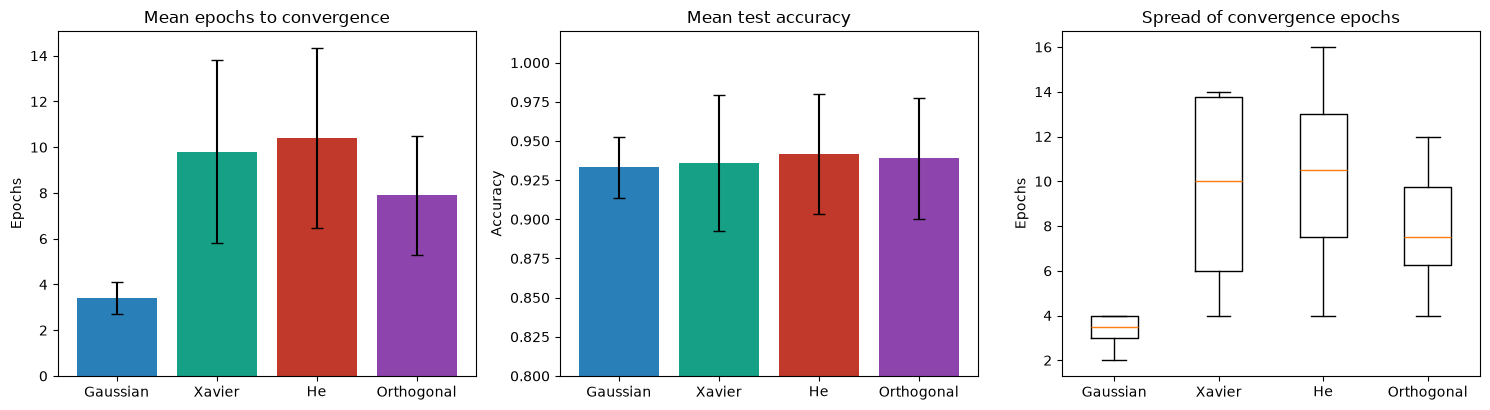

Fastest on average    : gaussian (3.40 epochs)
Most accurate average : he (0.9417)


In [36]:
# Zain Ul Wahaj | FA23-BAI-058 | Task 9 (c)
summary = runs.groupby("init").agg(
    runs_converged=("converged", "sum"),
    mean_conv_epoch=("conv_epoch", "mean"),
    std_conv_epoch=("conv_epoch", "std"),
    mean_test_acc=("test_acc", "mean"),
    std_test_acc=("test_acc", "std"),
    min_test_acc=("test_acc", "min"),
    max_test_acc=("test_acc", "max"),
).reindex(STRATEGIES).round(4)

print("AVERAGES ACROSS", len(SEEDS), "SEEDS")
print(summary.to_string())

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
names = [s.capitalize() for s in STRATEGIES]
bar_colours = [colours[s] for s in STRATEGIES]

axes[0].bar(names, summary["mean_conv_epoch"], yerr=summary["std_conv_epoch"],
            capsize=4, color=bar_colours)
axes[0].set_title("Mean epochs to convergence")
axes[0].set_ylabel("Epochs")

axes[1].bar(names, summary["mean_test_acc"], yerr=summary["std_test_acc"],
            capsize=4, color=bar_colours)
axes[1].set_title("Mean test accuracy")
axes[1].set_ylabel("Accuracy")
axes[1].set_ylim(0.8, 1.02)

axes[2].boxplot([runs[runs["init"] == s]["conv_epoch"].dropna() for s in STRATEGIES],
                tick_labels=names)
axes[2].set_title("Spread of convergence epochs")
axes[2].set_ylabel("Epochs")

plt.tight_layout()
plt.show()

fastest = summary["mean_conv_epoch"].idxmin()
most_accurate = summary["mean_test_acc"].idxmax()
print(f"Fastest on average    : {fastest} ({summary.loc[fastest, 'mean_conv_epoch']:.2f} epochs)")
print(f"Most accurate average : {most_accurate} ({summary.loc[most_accurate, 'mean_test_acc']:.4f})")

### Task 9 (d)

> Based on your experimental results, discuss how weight initialization, dataset characteristics, and randomness can influence perceptron training.

In [37]:
# Zain Ul Wahaj | FA23-BAI-058 | Task 9 (d)
acc_spread = summary["mean_test_acc"].max() - summary["mean_test_acc"].min()
epoch_spread = summary["mean_conv_epoch"].max() - summary["mean_conv_epoch"].min()
worst_std = summary["std_conv_epoch"].max()

print("DISCUSSION")
print("=" * 60)
print(f"""
WEIGHT INITIALISATION
   Averaged over {len(SEEDS)} seeds, mean convergence epochs differ by
   {epoch_spread:.2f} epochs between the fastest and slowest strategy, while mean
   test accuracy differs by only {acc_spread:.4f}. Initialisation therefore changed
   HOW LONG training took far more than WHERE it ended up. The ordering follows
   the starting weight norm: strategies that begin closer to zero need fewer
   updates before the data, rather than the random start, decides the direction
   of the weight vector.

DATASET CHARACTERISTICS
   This is the clearest result in the whole lab. On Wine (cultivar 0 vs rest) the
   classes are linearly separable, so the perceptron reaches zero training error
   and genuinely converges - the convergence theorem applies and a finite epoch
   count exists. On Breast Cancer in Tasks 2 to 8 the classes overlap, no straight
   line can separate them, and the error oscillated forever without reaching zero.
   The same algorithm with the same settings produced completely different
   behaviour purely because of the data. Separability decided whether 'convergence'
   was even a meaningful thing to measure.

RANDOMNESS
   The standard deviation of convergence epochs reaches {worst_std:.2f} for the most
   variable strategy. That is large next to the {epoch_spread:.2f}-epoch gap between
   strategy averages, which means a single run with a lucky seed can easily make
   one method look better than another when it is not. It is exactly why Task 8's
   single-run comparison could not settle anything and why averaging over several
   seeds was necessary. Randomness enters through the initial weights and through
   the train/test split; both shift results enough to reverse a ranking.

CONCLUSION
   For a single-layer perceptron, initialisation is a second-order concern. The
   data's separability sets the accuracy ceiling, the learning rate and epoch
   budget control how fast that ceiling is approached, and initialisation only
   adjusts the starting position slightly. Xavier, He and Orthogonal were built to
   keep signals stable through many layers - a problem a one-layer model does not
   have. Their advantages would only appear in a deep network.
""")

print("Final averaged results:")
print(summary[["runs_converged", "mean_conv_epoch", "mean_test_acc"]].to_string())

DISCUSSION

WEIGHT INITIALISATION
   Averaged over 10 seeds, mean convergence epochs differ by
   7.00 epochs between the fastest and slowest strategy, while mean
   test accuracy differs by only 0.0084. Initialisation therefore changed
   HOW LONG training took far more than WHERE it ended up. The ordering follows
   the starting weight norm: strategies that begin closer to zero need fewer
   updates before the data, rather than the random start, decides the direction
   of the weight vector.

DATASET CHARACTERISTICS
   This is the clearest result in the whole lab. On Wine (cultivar 0 vs rest) the
   classes are linearly separable, so the perceptron reaches zero training error
   and genuinely converges - the convergence theorem applies and a finite epoch
   count exists. On Breast Cancer in Tasks 2 to 8 the classes overlap, no straight
   line can separate them, and the error oscillated forever without reaching zero.
   The same algorithm with the same settings produced completely di

---

## End of Lab 03

All 9 tasks (36 parts) completed by **Zain Ul Wahaj** - **FA23-BAI-058**.